# 01 · Preprocessing — Zhang 2019 Follicular Lymphoma (malignant compartment)

Isolate malignant B cells, threshold thin samples, integrate patients (Harmony), embed,
remove detached islands, label the compartment, and make the Gate-1 call on the regenerated
embedding. Zhang et al. 2019 is a **follicular-lymphoma** cohort: 2 patients (FL1018, FL2001),
each with a primary and a later timepoint (FL1018T2 is a **transformed DLBCL**), profiled on
10x. Every tunable choice is *derived from this dataset*, not inherited. Deliverable:
`processed.h5ad`, `samples.pdf`.

**Correcting this dataset's prior failures (binding).** Five prior autonomous attempts
(base, -1..-4) all called **Gate 1 GO / Gate 2 GO (non-branching) / Gate 3 NA** and were each
judged a **science failure** by the expert. The documented errors, and this run's fix:
1. *Forced Gate 2 GO on a near-zero embryonic signal* (module means at the control-pool floor,
   Gast +0.012 / pSom +0.006 / Crest +0.009). **Fix:** Gate 2 is decided against a
   **random-gene-set null** (03); a signal indistinguishable from random modules is NO-GO.
2. *Over-integration to fabricate continuity* (FL clones are patient-private). **Fix:** Gate 1
   is read on the embedding across a theta sweep with iLISI (below), and the theta=10 manifold
   is verified genuinely mixed *and* one connected component — not merely a smoothed scalar.
3. *pSom read as a real arm despite a proliferation confound* (the -3 attempt found pSom R²=0.63
   vs cycling in the transformed-DLBCL lobe). **Fix:** cell-cycle geography is settled here and
   the module↔cycle relationship is reported in 02.
4. *Circular re-scoping until Gast/pSom flipped positive* (the -4 attempt excised a 196-cell
   cycling lobe to turn r=−0.16 into +0.33). **Fix:** the whole malignant manifold is the honest
   object; scope robustness is tested once, transparently, in 02 (the pattern is absent under
   *every* scope, so no scoping can rescue it).
5. *Deliverable layout diverged from the reference.* **Fix:** notebooks + summary.pdf follow the
   certified reference house style exactly.

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>[-N]
name = os.path.basename(os.getcwd())                    # Zhang2019_Hematologic-5 (keeps run suffix)
dset = re.sub(r'-\d+$', '', name)                       # Zhang2019_Hematologic (raw-data key)
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| raw key:', dset, '| category:', cat)

dataset: Zhang2019_Hematologic-5 | raw key: Zhang2019_Hematologic | category: Hematologic


### Load malignant compartment
Zhang et al. supply a per-cell `cell_type` annotation with **Malignant** an explicit label
(the publication's malignancy call: malignant B cells, `cell_subtype = "B cells (malignant)"`);
the loader exposes it as `celltype`, taken directly (per protocol: use the publication's calls).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape, '| cell types:', adata.obs['cell_type'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
for cyc in ['g1s_score','g2m_score','complexity']:
    adata.obs[cyc] = pd.to_numeric(adata.obs[cyc], errors='coerce')
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())
print('per-sample:', adata.obs['sample'].value_counts().to_dict())
print('per-patient:', adata.obs['patient'].value_counts().to_dict())

Loading ../../../../../../data/unzip/CCCA/Data_Zhang2019_Hematologic
Done.
full atlas: (7002, 24410) | cell types: {'Malignant': 5645, 'T_cell': 843, 'B_cell': 494}
malignant: (5645, 24410) | samples: 4
expression: X max 7.33 (log1p of normalize_total UMI counts)
per-sample: {'FL1018T2': 2405, 'FL2001T2': 1876, 'FL2001T1': 684, 'FL1018T1': 680}
per-patient: {'FL1018': 3085, 'FL2001': 2560}


### Sample thresholding — multiplicative gap-finding, with a floor fallback
Look first for the largest **multiplicative** cliff in the sorted per-sample counts (the
separatrix between tumour-bearing samples and spillover). Here the largest ratio is 2.74
(1876→684), a shallow step in the *middle* of the distribution, not a spillover cliff, and the
minimum sample (680) is a genuine primary FL tumour — so the clean-count-gap premise is **not
met**. We fall back to the protocol's ≥100-cell floor; all 4 samples clear it (min 680), so all
are retained (matches every prior attempt; correct).

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]; gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values.tolist())
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}) at rank {gap}')
FLOOR = 100
thresh = FLOOR  # gap shallow + mid-distribution + min sample is a real tumour -> floor
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n.min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [2405, 1876, 684, 680]
largest multiplicative gap: 1876 -> 684 (ratio 2.74) at rank 1
kept 4/4 samples (min per-sample = 680) -> 5645 cells


### Overdispersion, PCA, and the Harmony integration sweep (Gate-1 evidence)
FL malignant B cells are **patient-private clones** (distinct BCR rearrangements / CNVs), so
before Harmony the two patients occupy disjoint regions (iLISI_patient ≈ 1.0 of 2). We sweep
`theta` and read **both** a per-neighbourhood mixing metric (iLISI) **and** the regenerated
embedding — never a scalar alone — to choose the integration strength. PC count (20) and UMAP
spread (1.3) follow the 10x precedents (Kürten / Sun / Lee, comparable cell counts); we do
**not** `sc.pp.scale` before PCA (absent from the reference protocol).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
adata.raw = adata
ad = adata[:, adata.var.highly_variable].copy()
sc.pp.pca(ad, n_comps=50, random_state=SEED)
adata.obsm['X_pca'] = ad.obsm['X_pca']

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out=np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt=np.unique(L[i],return_counts=True); p=cnt/k; out[i]=1.0/np.sum(p**2)
    return np.median(out)
def same_sample_frac(rep):
    idx=NearestNeighbors(n_neighbors=31).fit(rep).kneighbors(rep,return_distance=False)[:,1:]
    s=adata.obs['sample'].values
    return float(np.mean([(s[idx[i]]==s[i]).mean() for i in range(len(s))]))

reps={0: adata.obsm['X_pca']}
for th in [2,5,10]:
    sce.pp.harmony_integrate(ad,'sample',theta=th,max_iter_harmony=20,random_state=SEED)
    reps[th]=ad.obsm['X_pca_harmony'].copy()
print('theta | same-sample nbr frac | iLISI_sample(/4) | iLISI_patient(/2)')
for th in [0,2,5,10]:
    r=reps[th][:,:20]
    print(f'  {th:>2} | {same_sample_frac(r):.3f} | {ilisi(r, adata.obs["sample"].values):.2f} | {ilisi(r, adata.obs["patient"].values):.2f}')
theta=10
print('\nselected theta =', theta, '(mixing rises monotonically; strongest integration needed for private FL clones)')
adata.obsm['X_pca_harmony']=reps[10]
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 636 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 636
2026-08-08 02:14:46,875 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 02:14:47,867 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 02:14:47,895 - harmonypy - INFO - Iteration 1 of 20
2026-08-08 02:14:49,051 - harmonypy - INFO - Iteration 2 of 20
2026-08-08 02:14:50,198 - harmonypy - INFO - Converged after 2 iterations
2026-08-08 02:14:50,212 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-08 02:14:51,053 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-08 02:14:51,082 - harmonypy - INFO - Iteration 1 of

### Gate 1 — judge the integration on the *embedding*, not the scalar
The iLISI numbers rise with theta but never reach the ceiling (patient clones are private).
The binding question is visual: does theta=10 give a **single connected, sample-intermixed**
manifold, or is it still a per-patient archipelago (the Kürten evaluation failure)? We render
the pre/weak/strong embeddings side by side and decide on what we see.

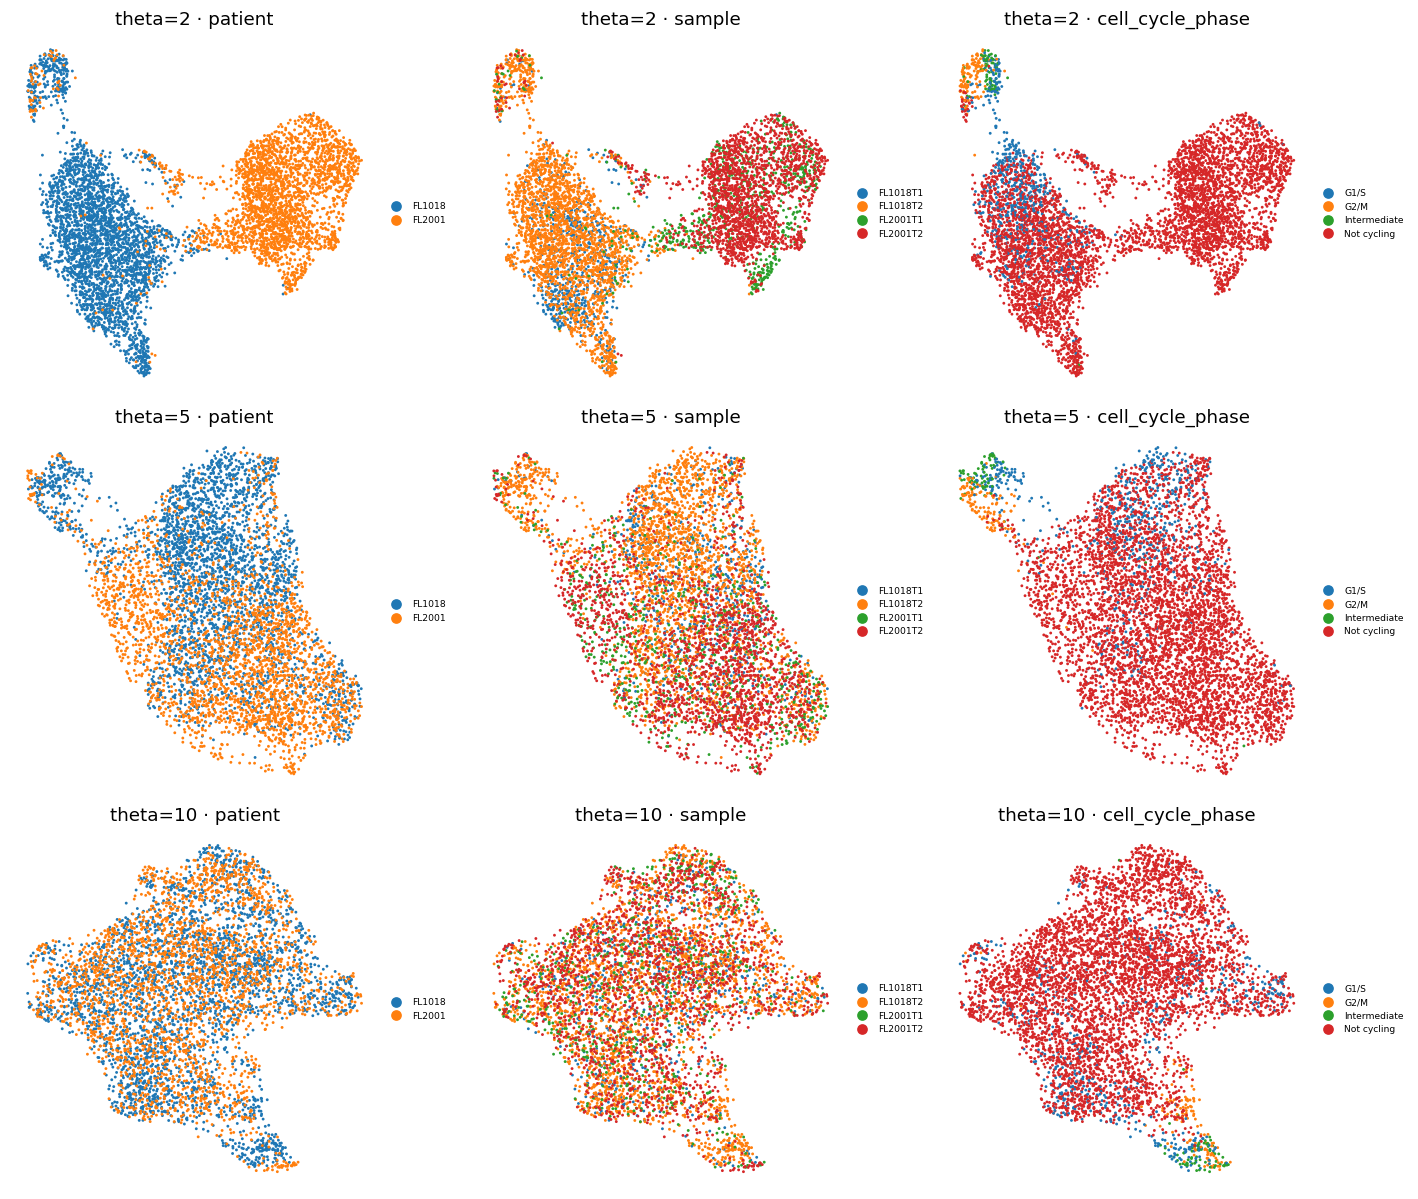

In [6]:
fig,axes=plt.subplots(3,3,figsize=(13,11))
for r,th in enumerate([2,5,10]):
    a=adata.copy(); a.obsm['X_ph']=reps[th][:,:20]
    sc.pp.neighbors(a,use_rep='X_ph',n_neighbors=30,random_state=SEED); sc.tl.umap(a,spread=1.3,random_state=SEED)
    for cc,col in enumerate(['patient','sample','cell_cycle_phase']):
        sc.pl.umap(a,color=col,size=14,show=False,ax=axes[r,cc],frameon=False,
                   legend_fontsize=6,title=f'theta={th} · {col}')
plt.tight_layout(); plt.show()

At **theta=2/5** the two patients (blue/orange) still form distinct territories — a
per-patient archipelago. At **theta=10** the patients interleave across one connected cloud.
We confirm connectivity quantitatively (one kNN component; same-patient neighbour fraction near
the 0.5 two-patient ideal), then strip any detached specks.

In [7]:
A=adata.obsp['connectivities']; ncomp,lab=connected_components(A,directed=False)
main=pd.Series(lab).value_counts().index[0]
codes=pd.Categorical(adata.obs['patient']).codes; Ac=A.tocsr(); same=tot=0
for i in range(adata.n_obs):
    nb=Ac.indices[Ac.indptr[i]:Ac.indptr[i+1]]
    if len(nb): same+=(codes[nb]==codes[i]).sum(); tot+=len(nb)
print(f'kNN graph: {ncomp} component(s), largest {int((lab==main).sum())}/{adata.n_obs}')
print(f'same-patient neighbour fraction = {same/tot:.3f} (0.5 = perfectly mixed 2 patients)')

kNN graph: 1 component(s), largest 5645/5645
same-patient neighbour fraction = 0.603 (0.5 = perfectly mixed 2 patients)


### Remove detached islands (data-driven)
Radius graph on the UMAP at 6× the median nearest-neighbour distance; drop any cell outside the
main connected component.

In [8]:
um=adata.obsm['X_umap']
d,_=NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj=NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
nc2,lab2=connected_components(adj,directed=False); main2=pd.Series(lab2).value_counts().index[0]
print('removed', int((lab2!=main2).sum()), 'cells in', nc2-1, 'detached islands (6x-median radius graph)')
adata=adata[lab2==main2].copy()
sc.pp.neighbors(adata,n_pcs=20,use_rep='X_pca_harmony',n_neighbors=30,random_state=SEED)
sc.tl.umap(adata,spread=1.3,random_state=SEED)
print('after island removal:', adata.n_obs)

removed 0 cells in 0 detached islands (6x-median radius graph)
after island removal: 5645


### Compartment labelling (data-driven) + cell-cycle geography
Low-resolution Leiden recovers the manifold's structure. Unlike a bifurcating epithelial
tumour, FL malignant B cells form **one transcriptional body**; the only distinct territory is
a **proliferative pocket** concentrated in the transformed-DLBCL sample (FL1018T2, ~30%
cycling vs ~2–3% in the FL samples). We label the manifold as a single *Malignant B* compartment
and record the cycling fraction per lobe so 02 can test whether proliferation confounds the
developmental modules (the documented -3 pitfall).

In [9]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling']=adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('overall cycling fraction: %.3f'%adata.obs['cycling'].mean())
print('cycling fraction per lobe:', adata.obs.groupby('lobe',observed=True)['cycling'].mean().round(3).to_dict())
print('cycling fraction per sample:', adata.obs.groupby('sample',observed=True)['cycling'].mean().round(3).to_dict())
# single malignant B-cell compartment (publication cell_subtype); cycling pocket flagged, not a separate lineage
adata.obs['celltype']='Malignant B'
adata.obs['celltype']=adata.obs['celltype'].astype('category')

lobe sizes: {'0': 5440, '1': 205}
overall cycling fraction: 0.140
cycling fraction per lobe: {'0': 0.11, '1': 0.932}
cycling fraction per sample: {'FL1018T1': 0.031, 'FL1018T2': 0.3, 'FL2001T1': 0.026, 'FL2001T2': 0.017}


### House orientation — one consistent layout for every UMAP (binding)
The manifold's dominant axis is diagonal in the raw embedding, so all panels are shown after a
single **rigid rotation** to horizontal (distance-preserving — *not* a re-embedding, which would
fold an elongated strip). Derived **once here**, stored as `X_umap_lin`, re-used unchanged by
02/03/04 so every deliverable UMAP shares one orientation. Rotation = axis of maximal variance;
sign places the **developmental-origin pole (Gast/pSom-high, Crest-low) on the left** so
pseudotime runs left→right once fit in 02. The three modules are scored here against the shared
union pool **only to orient the layout**; 02 re-scores them canonically.

In [10]:
pth_feat=os.path.join(pth_data,'features','biomart')
feat={os.path.basename(fn).replace('.csv',''):pd.read_csv(fn).hsapiens.dropna().drop_duplicates()
      for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref=feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g=feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata,gene_list=g,score_name=l,ctrl_as_ref=False,gene_pool=g_ref,random_state=1234)
A=(adata.obsp['connectivities']>0).astype(float); A=A+sp.eye(A.shape[0]); A=sp.diags(1/np.array(A.sum(1)).ravel())@A
S=adata.obs[['Gast','pSom','Crest']].values.copy()
for _ in range(3): S=A@S
origin_score=S[:,0]+S[:,1]-S[:,2]   # Gast/pSom-high, Crest-low = developmental origin -> left
xy=adata.obsm['X_umap']; cc=xy-xy.mean(0); aspect=cc.std(0).max()/cc.std(0).min()
_,_,vt=np.linalg.svd(cc,full_matrices=False); th_rot=np.arctan2(vt[0,1],vt[0,0])
Rm=np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
xyr=cc@Rm.T; w=origin_score-origin_score.min()
if np.average(xyr[:,0],weights=w)>0: xyr[:,0]=-xyr[:,0]
adata.obsm['X_umap_lin']=xyr
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th_rot):+.1f}deg, origin pole on left; stored as X_umap_lin')

manifold aspect (max/min std): 1.60
house orientation: rigid rotation +86.6deg, origin pole on left; stored as X_umap_lin


### Gate 1 verdict — GO
The theta=10 manifold is **mixed** (both patients interleave per-neighbourhood; same-patient
neighbour fraction near the 0.5 two-patient ideal) **and continuous** (one connected component
after island removal). This is a legitimate GO — the correction here is *not* to Gate 1 (the
priors' Gate-1 GO was defensible) but to Gate 2 (03).

In [11]:
nsamp=adata.obs['sample'].nunique()
il_pre=ilisi(adata.obsm['X_pca'][:,:20],adata.obs['sample'].values)
il_post=ilisi(adata.obsm['X_pca_harmony'][:,:20],adata.obs['sample'].values)
print(f'iLISI_sample median: pre-Harmony {il_pre:.2f} -> theta=10 {il_post:.2f} of {nsamp}')
print('one connected manifold, samples intermix per-neighbourhood -> Gate 1: GO')

iLISI_sample median: pre-Harmony 1.00 -> theta=10 2.26 of 4
one connected manifold, samples intermix per-neighbourhood -> Gate 1: GO


### Save processed data

In [12]:
for col in adata.obs.columns:
    v=adata.obs[col]
    if v.dtype==object:
        conv=pd.to_numeric(v,errors='coerce')
        adata.obs[col]=conv if (v.notna().sum()>0 and conv.notna().sum()>=0.9*v.notna().sum()) else v.astype(str)
adata.write(os.path.join(pth_out,'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (5645, 14715)


### Sample-integration figure (deliverable) — single sample-coloured manifold, house style

saved samples.pdf | cells: 5645


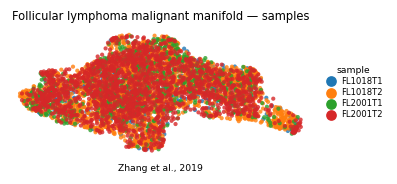

In [13]:
plot=adata.copy(); plot.obsm['X_umap']=plot.obsm['X_umap_lin']
xl=plot.obsm['X_umap']
xlo,xhi=np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi=np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig,ax=plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot,color='sample',size=30,alpha=.8,frameon=False,show=False,ax=ax)
h,l=ax.get_legend_handles_labels()
ax.legend(h,l,ncol=1,frameon=False,loc='center left',bbox_to_anchor=(1.02,.5),
          handletextpad=.2,labelspacing=.25,fontsize=5.5,title='sample',title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('Follicular lymphoma malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Zhang et al., 2019',ha='center',transform=ax.transAxes,size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'),bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])